# 08 · Features and models

**Goal:** see exactly what the machine-learning models are given, why we predict a *change* rather than a *level*, how much each feature group adds, and what a model actually relies on.

We use the tutorial's compact feature builder (`tutorial_utils.build_features`, 25 features) - a simplified cousin of the pipeline's 55. We build a few features by hand first, then call the builder.

In [1]:
from tutorial_utils import *
style()
rl = load_panel("realistic")
raw = wide(rl, "wholesale_price_kes_kg")
accepted, _ = clean_price_wide(raw)
price = accepted.ffill(limit=8); lp = np.log(price)
s = "MKT-01|CRP-02"                       # Nairobi tomatoes

## Feature 1 - price momentum, built by hand
`lr_4` = log price now minus log price four weeks ago ("how much has the price moved over the last month?"). In pandas that is a shift: `shift(4)` looks **backwards**, so it is as-known by construction.

In [2]:
demo = pd.DataFrame({"price": price[s], "lr_4": lp[s] - lp[s].shift(4), "dev_mean_4": lp[s] - lp[s].rolling(4, min_periods=2).mean()}).loc[96:104]
demo.round(3)

,price,lr_4,dev_mean_4
week_index,,,
96,98.11,0.124,0.167
97,94.07,0.224,0.069
98,87.51,0.153,-0.042
99,95.32,0.105,0.017
100,104.27,0.061,0.092
101,109.99,0.156,0.106
102,108.96,0.219,0.042
103,101.21,0.060,-0.047
104,84.01,-0.216,-0.179


`dev_mean_4` is the gap between the current price and its 4-week average: positive when the price is above its recent norm - a mean-reversion signal. `vol_8` (std of the last 8 weekly changes) measures recent turbulence.

## Feature 2 - the horizon-specific seasonal reference
Weeks `t + h − 52` exist at the origin (they are in the past), so "what was the price one year before the *target* week?" is legitimately known. The feature is the log gap between that value and today's price.
Because it depends on `h`, the feature table is rebuilt for each horizon (`build_features(rl, h)`).

## Feature 3 - calendar facts about the *target* week
Date arithmetic (`week → date → day of year → sin/cos`) tells us the season of the target week. No data are involved, so it is knowable in advance. What we **may not** use are *events* of future weeks (a demand surge next month): nobody knows them in advance.

## Feature 4 - an indicator that arrives late
For a delayed record the as-known value at lag 0 is missing; with data handling we fall back to the previous week's value:

In [3]:
arr = wide(rl, "market_arrivals_tonnes").ffill(limit=4); dl = wide(rl, "report_delay_weeks")
k = "MKT-04|CRP-03"
chk = pd.DataFrame({"arrivals (week w)": arr[k], "delay flag": dl[k], "as-known at origin w": arr[k].where(dl[k] == 0).fillna(arr[k].shift(1))}).loc[48:56]
chk.round(1)

,arrivals (week w),delay flag,as-known at origin w
week_index,,,
48,201.0,0,201.0
49,173.0,0,173.0
50,152.6,0,152.6
51,162.6,0,162.6
52,138.6,0,138.6
53,137.8,1,138.6
54,124.6,0,124.6
55,149.1,0,149.1
56,139.1,0,139.1


On rows with `delay flag = 1` the "as-known" value is last week's value, not the (not yet delivered) current one.

## Feature 5 - cross-market information
For each market the generator defines which markets supply it and with what weight (`network` in the config). Two features: the weighted log price of the *source* markets minus the market's own log price (`conn_gap0`) and the source markets' price change last week (`conn_chg1`);
plus the regional supply index. These implement the "one market's shock reaches its neighbours a week later" mechanism.

In [4]:
print(network_weights()["MKT-01"], " <- sources of Nairobi and their weights")

{'MKT-02': 0.5, 'MKT-03': 0.35, 'MKT-04': 0.15}  <- sources of Nairobi and their weights


## The feature table
One row per (series, origin week); one column per feature. Groups can be switched on cumulatively - the **ablation sets** E0 … E4.

In [5]:
f2 = build_features(rl, 2)
print(f"{len(f2)} rows x {len(columns_for(list(FEATURE_GROUPS)))} features")
print(pd.DataFrame({g: [", ".join(cs)] for g, cs in FEATURE_GROUPS.items()}, index=["features"]).T.to_string())
print("\nshare of missing values per group (before any imputation):")
print(pd.Series({g: f2[cs].isna().mean().mean() for g, cs in FEATURE_GROUPS.items()}).round(3).to_string())

2820 rows x 25 features
                                                                                              features
price          lr_1, lr_2, lr_4, lr_8, lr_13, dev_mean_4, dev_mean_8, dev_mean_13, vol_8, seasonal_ref
calendar                                                        tgt_sin1, tgt_cos1, tgt_sin2, tgt_cos2
supply_demand                                                                   arr_anom13, dem_anom13
weather                                               rain_mean4, rain_sum13, drought_l0, drought_max8
logistics                                                                        fuel_chg4, trans_chg4
cross_market                                                           conn_gap0, conn_chg1, regsup_l0

share of missing values per group (before any imputation):
price            0.026
calendar         0.000
supply_demand    0.000
weather          0.000
logistics        0.000
cross_market     0.000


Missing values remain (e.g. the first weeks of each series have no 13-week history). The models handle them differently: Ridge and the random forest get a **median imputation fitted on the training rows only**; gradient boosting handles missing values natively.

## Why predict the change, not the level?
Compare two gradient-boosting models: one predicts `log(price[t+h]/price[t])` (change, our standard), the other predicts the log *level* directly using the current log price as a feature.

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
cols4 = columns_for(ABLATION_SETS["E4 +cross-market"])

def level_target_skill(h, train_end, lo, hi):
    f = build_features(rl, h); f["lp0"] = np.log(f.ref_price)
    ok = f.ref_price.notna() & f.y_obs.notna() & (f.y_obs > 0) & ~f.y_rejected
    tr = f[ok & (f.origin_week <= train_end - h)]; ev = f[(f.origin_week.between(lo, eval_hi(h, hi))) & f.ref_price.notna() & f.y_obs.notna() & ~f.y_suspect]
    c = cols4 + ["lp0"]
    m = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=150, max_depth=3, random_state=0).fit(tr[c], np.log(tr.y_obs))
    pred = np.exp(m.predict(ev[c]))
    return 1 - mae(ev.y_obs, pred) / mae(ev.y_obs, ev.ref_price)

def change_target_skill(h, train_end, lo, hi):
    f = build_features(rl, h)
    return 1 - score(fit_predict(f, cols4, "hist_gb", h, train_end, lo, eval_hi(h, hi))) / score(naive_pred(f, lo, eval_hi(h, hi)))

rows = []
for h in HORIZONS:
    rows.append(dict(horizon=h, target="change (standard)", validation_skill=change_target_skill(h, TRAIN_END, TRAIN_END + 1, VAL_END) * 100, test_skill=change_target_skill(h, VAL_END, VAL_END + 1, TEST_END) * 100))
    rows.append(dict(horizon=h, target="level", validation_skill=level_target_skill(h, TRAIN_END, TRAIN_END + 1, VAL_END) * 100, test_skill=level_target_skill(h, VAL_END, VAL_END + 1, TEST_END) * 100))
pd.DataFrame(rows).round(1)

,horizon,target,validation_skill,test_skill
0,1,change (standard),14.0,2.6
1,1,level,9.5,-10.0
2,2,change (standard),20.0,0.9
3,2,level,13.2,-3.1
4,4,change (standard),16.9,1.5
5,4,level,13.6,-3.1


Predicting the level makes a tree ensemble re-learn "tomorrow ≈ today" from scratch with piecewise-constant steps, and it can never predict outside the range of levels it saw. Predicting the *change relative to the latest price*
starts from the naive forecast and asks the model only for the correction. In this run the level target is consistently worse - by about 4-7 skill points on validation and 4-13 on test, where it falls clearly below naive. This design choice explains why the models never collapse far below naive.

## Models and the effect of the extra information
We fit Ridge, a random forest and gradient boosting with the price-only set (E0) and the full set (E4), for each horizon, on **validation** (train ≤ 104 − h) and **test** (train ≤ 130 − h).
Hyper-parameters here are sensible defaults - tuning is notebook 09.

In [7]:
def run(kind, groups_name, h, part):
    f = build_features(rl, h); cols = columns_for(ABLATION_SETS[groups_name])
    tr_end, lo, hi = (TRAIN_END, TRAIN_END + 1, VAL_END) if part == "validation" else (VAL_END, VAL_END + 1, TEST_END)
    p = fit_predict(f, cols, kind, h, tr_end, lo, eval_hi(h, hi), **({"alpha": 100.0} if kind == "ridge" else {}))
    n = naive_pred(f, lo, eval_hi(h, hi))
    return score(p), score(n)

rows = []
for part in ("validation", "test"):
    for kind in ("ridge", "random_forest", "hist_gb"):
        for g in ("E0 price+calendar", "E4 +cross-market"):
            for h in HORIZONS:
                m, n = run(kind, g, h, part)
                rows.append(dict(partition=part, model=kind, features=g[:2], horizon=h, skill=(1 - m / n) * 100))
res = pd.DataFrame(rows)
print("skill vs naive (%):")
res.pivot_table(index=["partition", "model", "features"], columns="horizon", values="skill").round(1)

skill vs naive (%):


horizon                               1     2     4
partition  model         features                  
test       hist_gb       E0       -10.9  -8.5  -7.4
                         E4         2.6   0.9   1.5
           random_forest E0        -9.2  -9.1  -4.0
                         E4         1.5   2.7   1.9
           ridge         E0        -2.5  -4.7  -5.4
                         E4         8.8  10.7   5.7
validation hist_gb       E0         3.3   7.7   6.8
                         E4        14.0  20.0  16.9
           random_forest E0         5.5   8.2  16.4
                         E4        14.8  18.5  19.4
           ridge         E0         5.6   5.3   6.0
                         E4        17.4  18.9  14.0

Two things stand out already. **On the test window the price-only (E0) models are all worse than naive** (negative skill), while the enriched (E4) models are at or above naive. And the *ordering* of the three model types
is not stable: untuned Ridge looks best on the test window here. Do not over-read it - notebook 09 shows that these differences are mostly inside the noise.

Compare with the pipeline's own test numbers (`results/ablation_test_MAE.csv`; tuned models, 55 features). The shape agrees - enriched beats price-only for every model, and the benefit is larger at horizons 1-2 than at 4 - while the absolute numbers differ:

In [8]:
pipe_abl = pd.read_csv(RESULTS / "ablation_test_MAE.csv", index_col=[0, 1])
pipe_naive = pd.read_csv(RESULTS / "core_eight_MAE_test.csv", index_col=0).loc["Naive"]
pa = pipe_abl.loc[[("ridge", "E0"), ("ridge", "E4"), ("random_forest", "E0"), ("random_forest", "E4"), ("hist_gb", "E0"), ("hist_gb", "E4")], ["1", "2", "4"]]
((1 - pa / pipe_naive[["1", "2", "4"]].values) * 100).round(1).rename(columns=lambda c: f"pipeline skill % h={c}")

pipeline skill % h=1  pipeline skill % h=2  \
model         feature_set                                               
ridge         E0                           -1.3                  -4.1   
              E4                            8.6                  10.9   
random_forest E0                           -7.1                  -7.7   
              E4                            6.2                   3.5   
hist_gb       E0                           -4.3                  -7.3   
              E4                            6.7                   2.2   

                           pipeline skill % h=4  
model         feature_set                        
ridge         E0                           -5.8  
              E4                            1.4  
random_forest E0                            1.3  
              E4                            8.1  
hist_gb       E0                            6.4  
              E4                            9.6

## Ablation: what does each feature group add?
Add the groups one at a time (price+calendar → +supply/demand → +weather → +logistics → +cross-market) with gradient boosting, at each horizon, on the **test** window.

horizon,1,2,4
feature_set,,,
E0 price+calendar,4.59,6.39,9.10
E1 +supply/demand,4.60,6.54,9.05
E2 +weather,4.46,6.39,8.45
E3 +logistics,4.42,6.27,8.52
E4 +cross-market,4.03,5.83,8.35


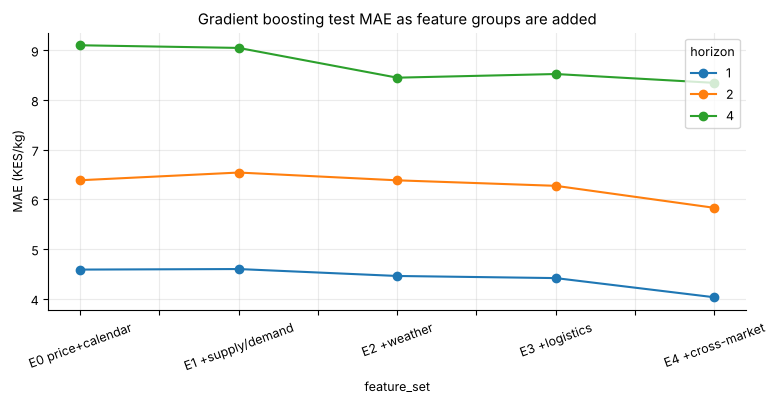

In [9]:
rows = []
for name in ABLATION_SETS:
    for h in HORIZONS:
        f = build_features(rl, h)
        p = fit_predict(f, columns_for(ABLATION_SETS[name]), "hist_gb", h, VAL_END, VAL_END + 1, eval_hi(h, TEST_END))
        rows.append(dict(feature_set=name, horizon=h, MAE=score(p)))
abl = pd.DataFrame(rows).pivot(index="feature_set", columns="horizon", values="MAE")
ax = abl.plot(marker="o", title="Gradient boosting test MAE as feature groups are added"); ax.set_ylabel("MAE (KES/kg)"); plt.xticks(rotation=20)
abl.round(2)

**What to look for.** The curve is *not* a smooth staircase down. Adding supply/demand changes almost nothing (the error even ticks *up* at h = 1 and 2). The **cross-market** step gives the clearest improvement at horizons 1 and 2 (about 0.4 KES/kg),
while at horizon 4 the biggest single step is **weather** (about 0.6) - consistent with weather causes working through delayed supply (notebook 02, Step 5), which only pays off at longer leads. Logistics add little. A group that does not help is a normal result and not a bug: a feature that is *present* in the data is not necessarily *predictive at the forecast lead time*. In the generator, price reacts to the **same-week** supply, which is not known at the origin;
only its persistence and the delayed weather causes are forecastable, and that part is small compared with the price noise. Extra features also add variance for a model with ~2,000 training rows.

## What does the model lean on? Group permutation importance
Take the fitted model, evaluate it on the validation rows, then **shuffle all columns of one feature group together** across rows and see how much the error increases. A big increase = the model relied on that group.

,h=1,h=2,h=4
price,0.231,0.734,1.000
calendar,0.021,0.138,0.059
supply_demand,0.245,0.362,0.217
weather,0.034,0.091,0.091
logistics,0.004,-0.005,0.036
cross_market,0.503,0.779,0.276


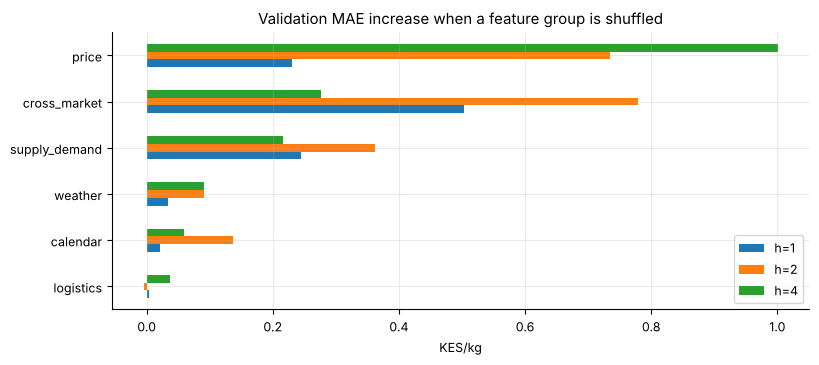

In [10]:
def group_importance(h, n_rep=5, seed=0):
    f = build_features(rl, h)
    p = fit_predict(f, cols4, "hist_gb", h, TRAIN_END, TRAIN_END + 1, VAL_END)
    pipe = p.attrs["pipeline"]; ev = p[p.scored]
    X = ev[cols4 + ["market_id", "crop_id"]]
    predict = lambda Z: ev.ref_price.values * np.exp(np.clip(pipe.predict(Z), -1.2, 1.2))
    base = mae(ev.y_obs, predict(X)); rng = np.random.default_rng(seed); out = {}
    for g, cs in FEATURE_GROUPS.items():
        inc = []
        for _ in range(n_rep):
            Z = X.copy(); Z[cs] = X[cs].values[rng.permutation(len(X))]
            inc.append(mae(ev.y_obs, predict(Z)) - base)
        out[g] = np.mean(inc)
    return pd.Series(out, name=f"h={h}")
imp = pd.concat([group_importance(h) for h in HORIZONS], axis=1)
ax = imp.sort_values("h=4").plot.barh(title="Validation MAE increase when a feature group is shuffled"); ax.set_xlabel("KES/kg")
imp.round(3)

Compare with the pipeline's version (`results/feature_group_importance_validation.csv`, 55 features):

In [11]:
pi = pd.read_csv(RESULTS / "feature_group_importance_validation.csv").pivot(index="group", columns="horizon", values="mae_increase")
pi.round(3).rename(columns=lambda c: f"pipeline h={c}")

horizon,pipeline h=1,pipeline h=2,pipeline h=4
group,,,
calendar,0.029,0.116,0.422
cross_market,0.538,0.715,0.364
identifiers,0.004,0.011,0.094
logistics,0.005,-0.000,0.011
price,0.347,0.757,1.431
supply_demand,0.108,0.153,0.139
weather,0.017,0.065,0.120


The two agree on the broad picture: **price-history features and cross-market information dominate** (cross-market is the largest at horizons 1-2, price history at horizon 4), weather and logistics carry little weight *in this validation window*.
They differ in the details - in the pipeline's richer feature set, the calendar group becomes important at horizon 4 (0.42) while in the tutorial it does not (0.06), and supply/demand matters more in the tutorial (0.2-0.4) than in the pipeline (0.1-0.15) - a reminder that importances depend on which other features are present.
The logistics result is instructive: transport costs barely varied before week 140, so a model trained on weeks ≤ 130 had nothing to learn from them - and could not possibly have anticipated the transport-cost shift of the test window (notebook 10).

**A word of caution.** Importance describes what *this model* relied on in *these data*; it does not prove the feature causes price changes, and importances between correlated features are unstable.
Here we have a rare luxury: the generator tells us the true mechanisms, so we can check that importances are plausible (a sanity check, not a proof). On real data you will not have that.

## Exercises
1. Add a feature of your own to `build_features` in a copy of `tutorial_utils.py` - for example the 26-week high of log price minus today's. Does the truncation test of notebook 05 pass? Does E4 improve?
2. Remove `market_id` / `crop_id` (`include_ids=False` in `fit_predict`). How much skill is lost? Which crop loses most?
3. Fit Ridge **separately for each crop**. Does it beat the global Ridge? (A preview of the "Ridge + crop interactions" result in the final report.)
4. Re-run the importance cell with `n_rep = 20`. How stable are the *rankings* of the groups?

**Where this lives in the pipeline:** `src/agriprice/features.py` (feature groups, `FeatureStore`), `src/agriprice/models.py` (`build_pipeline`, `fit_predict_ml`), `src/agriprice/analysis.py` (`group_permutation_importance`).